# Marker, ChArUco board and red-cube detection from one image

Given one image from the wrist camera (a saved file, or a live capture), this notebook:

1. **Finds ArUco markers.** It tries every OpenCV dictionary, so you don't need to know which one your board uses.
2. **Identifies the ChArUco board.** It searches grid sizes and marker-to-square ratios for the layout that best explains the markers, then finds the chessboard corners.
3. **Estimates the board's pose** (position and tilt relative to the camera). It uses `wrist_intrinsics.json` if it exists, otherwise a rough guess.
4. **Detects the red cube** with an HSV colour threshold.
5. **Locates the cube on the board**, by intersecting the camera ray through the cube with the plane of its top face.

Edit the settings in the next cell, then run all cells. You need `opencv-python` (4.7 or later), `numpy` and `matplotlib`.

In [ ]:
from pathlib import Path

IMAGE_PATH = None            # e.g. "../data/wrist_capture.jpg"; None = capture a live frame from the camera
CAMERA_INDEX = 0             # wrist camera (index 1 is the laptop webcam on this machine)
WIDTH, HEIGHT = 640, 480     # capture resolution (must match the intrinsics, if you have them)
INTRINSICS_PATH = Path("../calibration/wrist_intrinsics.json")

# Board: None = identify automatically, or set it, e.g.
# BOARD = dict(dictionary="DICT_4X4_50", squares_x=5, squares_y=7, marker_ratio=22 / 30, legacy=False)
BOARD = None
SQUARE_MM = 30.0             # measured size of one black square (sets the scale of every distance)

DETECT_UPSCALE = 2           # detect on an enlarged image: small markers decode much more reliably

CUBE_SIZE_MM = 25.0
HSV = dict(h_low_max=10, h_high_min=170, s_min=120, v_min=70, min_area=80)

In [ ]:
import json
import math

import cv2
import matplotlib.pyplot as plt
import numpy as np

print("OpenCV", cv2.__version__)
plt.rcParams["figure.figsize"] = (10, 7)


def draw_axes(rgb_img, K, dist, rvec, tvec, length):
    # drawFrameAxes uses BGR colours; draw on a BGR copy so x is red, y green, z blue
    bgr_img = cv2.cvtColor(rgb_img, cv2.COLOR_RGB2BGR)
    cv2.drawFrameAxes(bgr_img, K, dist, rvec, tvec, length, 3)
    return cv2.cvtColor(bgr_img, cv2.COLOR_BGR2RGB)


def show(img, title=""):
    plt.figure()
    plt.imshow(img)
    plt.title(title)
    plt.axis("off")
    plt.show()

OpenCV 4.13.0


## 1. Load or capture the image

Captured and saved wrist_capture.jpg
Image 640x480, mean brightness 63/255


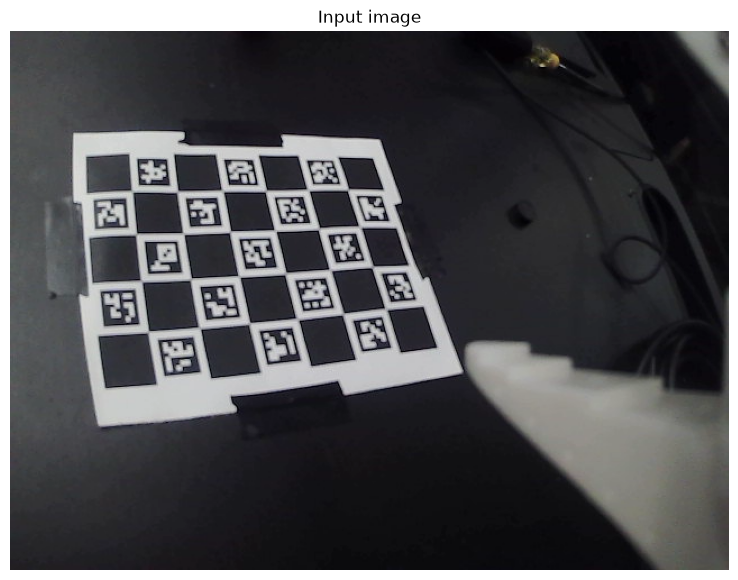

In [ ]:
if IMAGE_PATH is None:
    cap = cv2.VideoCapture(CAMERA_INDEX)
    cap.set(cv2.CAP_PROP_FRAME_WIDTH, WIDTH)
    cap.set(cv2.CAP_PROP_FRAME_HEIGHT, HEIGHT)
    for _ in range(30):  # let auto-exposure settle
        ok, bgr = cap.read()
    cap.release()
    if not ok:
        raise RuntimeError(f"Could not read from camera {CAMERA_INDEX}")
    cv2.imwrite("../data/wrist_capture.jpg", bgr)
    print("Captured and saved ../data/wrist_capture.jpg")
else:
    bgr = cv2.imread(str(IMAGE_PATH))
    if bgr is None:
        raise FileNotFoundError(IMAGE_PATH)
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
h_img, w_img = gray.shape
print(f"Image {w_img}x{h_img}, mean brightness {gray.mean():.0f}/255" + ("  <- very dark: lens cap?" if gray.mean() < 10 else ""))
show(rgb, "Input image")

## 2. ArUco markers: try every dictionary

Each dictionary is a different family of marker patterns. The right one usually decodes the most markers, with small, close-together IDs (boards number their markers from 0). A wrong dictionary sometimes decodes a few markers by accident, with scattered IDs.

**Why some markers are missed:** a 6×6 marker is 8 cells across including its black border. At 640×480 a marker on the table may be only ~20 px wide, so each bit covers ~2.5 px, and blur, glare or a steep viewing angle make it unreadable. Detection runs on an image enlarged `DETECT_UPSCALE` times, with settings that read more pixels per bit and correct more bit errors. Getting closer, looking more straight-on, better light, or a higher capture resolution all help further.

In [ ]:
DICT_NAMES = sorted({n.upper(): n for n in dir(cv2.aruco) if n.startswith("DICT_")}.values())


def detector_params():
    p = cv2.aruco.DetectorParameters()
    p.perspectiveRemovePixelPerCell = 8          # read more pixels per marker bit
    p.perspectiveRemoveIgnoredMarginPerCell = 0.2
    p.errorCorrectionRate = 0.8                  # accept a few misread bits
    p.adaptiveThreshWinSizeMin, p.adaptiveThreshWinSizeMax, p.adaptiveThreshWinSizeStep = 3, 33, 4
    p.cornerRefinementMethod = cv2.aruco.CORNER_REFINE_SUBPIX
    return p


s_up = DETECT_UPSCALE
gray_up = cv2.resize(gray, None, fx=s_up, fy=s_up, interpolation=cv2.INTER_CUBIC) if s_up > 1 else gray


def to_original(points):
    # map coordinates from the enlarged image back to the original (resize aligns pixel centres)
    return (points - (s_up - 1) / 2) / s_up


def detect_markers(dict_name):
    dictionary = cv2.aruco.getPredefinedDictionary(getattr(cv2.aruco, dict_name))
    corners, ids, _ = cv2.aruco.ArucoDetector(dictionary, detector_params()).detectMarkers(gray_up)
    return [to_original(c) for c in corners], ids


marker_hits = []
for name in DICT_NAMES:
    corners, ids = detect_markers(name)
    if ids is not None:
        marker_hits.append((len(ids), name, sorted(ids.ravel().tolist())))
# Most markers first; on a tie prefer the smallest dictionary (DICT_4X4_50 is a subset of _100, _250, ...).
dict_size = lambda name: int(name.rsplit("_", 1)[1]) if name.rsplit("_", 1)[1].isdigit() else 10**6
marker_hits.sort(key=lambda h: (-h[0], dict_size(h[1])))
print(f"{'markers':>7}  dictionary              ids")
for n, name, ids in marker_hits[:8]:
    print(f"{n:7d}  {name:22s}  {ids[:15]}{' ...' if len(ids) > 15 else ''}")
if not marker_hits:
    print("No markers found. Get closer, look at the board less obliquely, and avoid glare.")

markers  dictionary              ids
     16  DICT_ARUCO_MIP_36h12    [15, 20, 26, 43, 58, 59, 61, 70, 92, 93, 97, 121, 140, 149, 190] ...
     15  DICT_6X6_50             [0, 1, 2, 4, 5, 6, 8, 9, 10, 11, 12, 13, 14, 15, 16]
     15  DICT_6X6_100            [0, 1, 2, 4, 5, 6, 8, 9, 10, 11, 12, 13, 14, 15, 16]
     15  DICT_6X6_250            [0, 1, 2, 4, 5, 6, 8, 9, 10, 11, 12, 13, 14, 15, 16]
     14  DICT_6X6_1000           [0, 1, 2, 4, 5, 6, 8, 9, 10, 11, 12, 13, 14, 16]
      1  DICT_4X4_50             [32]
      1  DICT_4X4_100            [32]
      1  DICT_4X4_250            [32]


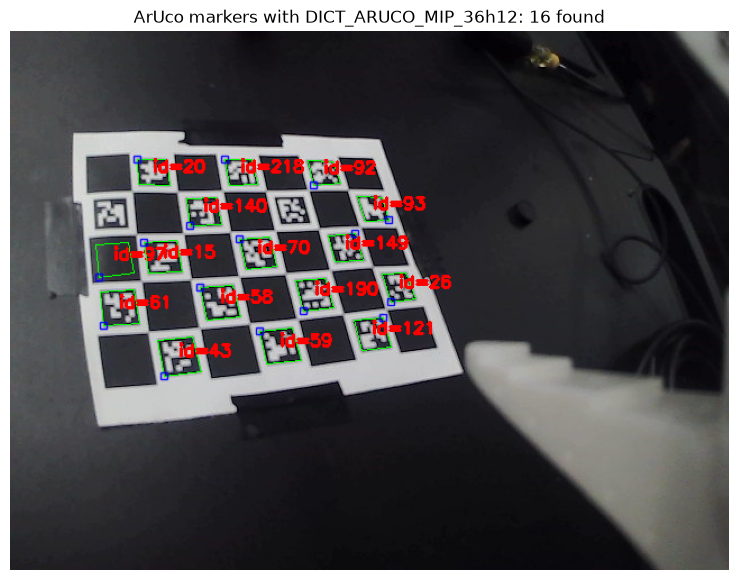

In [ ]:
if marker_hits:
    best_dict = (BOARD or {}).get("dictionary") or marker_hits[0][1]
    corners, ids = detect_markers(best_dict)
    view = rgb.copy()
    if ids is not None:
        cv2.aruco.drawDetectedMarkers(view, corners, ids)
    show(view, f"ArUco markers with {best_dict}: {0 if ids is None else len(ids)} found")

## 3. Identify the ChArUco board layout

A ChArUco board puts a marker in every white square. Once the layout is known (squares across and down, marker size relative to the square), each decoded marker predicts where its neighbouring chessboard corners are. Those corners are what calibration uses, because they're located far more precisely than marker edges. The search tries layouts for the most likely dictionaries and keeps the one that recovers the most corners. Square size doesn't matter for detection; it only sets the scale later.

"Legacy" covers boards made before OpenCV 4.6 that have an even number of rows; their pattern is shifted by one square.

Identified board: {'dictionary': 'DICT_6X6_50', 'squares_x': 7, 'squares_y': 5, 'marker_ratio': 0.663, 'legacy': False}  (19 corners; marker ratio measured from the image)
ChArUco corners: 19 of 24


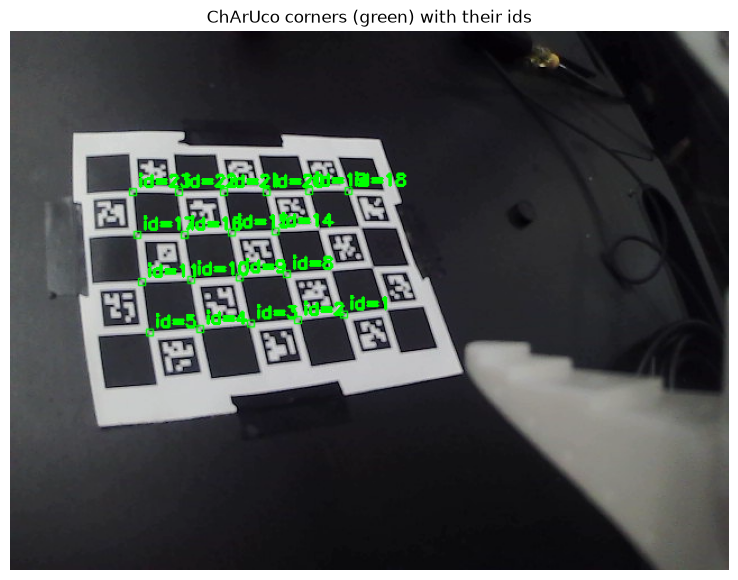

In [ ]:
def make_board(dictionary, squares_x, squares_y, marker_ratio, legacy, square_m=1.0):
    d = cv2.aruco.getPredefinedDictionary(getattr(cv2.aruco, dictionary))
    board = cv2.aruco.CharucoBoard((squares_x, squares_y), square_m, square_m * marker_ratio, d)
    board.setLegacyPattern(legacy)
    return board


def charuco_corners(board):
    detector = cv2.aruco.CharucoDetector(board, cv2.aruco.CharucoParameters(), detector_params())
    corners, ids, _, _ = detector.detectBoard(gray_up)
    return (to_original(corners), ids) if ids is not None and len(ids) >= 4 else (None, None)


def identify_board(candidate_dicts):
    best = None
    for dict_name, marker_ids in candidate_dicts:
        needed = max(marker_ids) + 1
        for sx in range(3, 15):
            for sy in range(3, 15):
                if (sx * sy) // 2 < needed:  # layout has too few markers for the ids seen
                    continue
                for ratio in (0.5, 0.6, 0.7, 0.75, 0.8):
                    for legacy in (False, True):
                        if legacy and sy % 2 == 1:
                            continue  # legacy only differs for an even number of rows
                        c, i = charuco_corners(make_board(dict_name, sx, sy, ratio, legacy))
                        n = 0 if i is None else len(i)
                        if n and (best is None or n > best[0]):
                            best = (n, dict(dictionary=dict_name, squares_x=sx, squares_y=sy, marker_ratio=ratio, legacy=legacy))
    return best


if BOARD is None:
    candidates = [(name, ids) for n, name, ids in marker_hits[:3] if n >= 2]
    found = identify_board(candidates) if candidates else None
    if found is None:
        raise RuntimeError("Could not identify a ChArUco board. Try a closer, straighter view of the board.")
    n_corners, BOARD = found
    # Every marker ratio finds the same corners, so measure the ratio instead: map the detected
    # marker corners into board coordinates (units of one square) and average their side length.
    b = make_board(**BOARD)
    c, i = charuco_corners(b)
    obj, img_pts = b.matchImagePoints(c, i)
    h_img2board, _ = cv2.findHomography(img_pts.reshape(-1, 2), obj.reshape(-1, 3)[:, :2])
    m_corners, m_ids = detect_markers(BOARD["dictionary"])
    sides = []
    for quad in m_corners:
        q = cv2.perspectiveTransform(quad.reshape(-1, 1, 2).astype(np.float64), h_img2board).reshape(-1, 2)
        sides += [np.linalg.norm(q[k] - q[(k + 1) % 4]) for k in range(4)]
    BOARD["marker_ratio"] = round(float(np.median(sides)), 3)
    print(f"Identified board: {BOARD}  ({n_corners} corners; marker ratio measured from the image)")
else:
    print(f"Using the configured board: {BOARD}")

board = make_board(**BOARD, square_m=SQUARE_MM / 1000)
ch_corners, ch_ids = charuco_corners(board)
total = (BOARD["squares_x"] - 1) * (BOARD["squares_y"] - 1)
print(f"ChArUco corners: {0 if ch_ids is None else len(ch_ids)} of {total}")
view = rgb.copy()
if ch_ids is not None:
    cv2.aruco.drawDetectedCornersCharuco(view, ch_corners, ch_ids, (0, 255, 0))
show(view, "ChArUco corners (green) with their ids")

## 4. Camera intrinsics and board pose

`solvePnP` finds the board pose that best lines up its known corner positions (in mm) with where they were seen in the image. That needs the camera's intrinsics (focal length, image centre, lens distortion). Without `wrist_intrinsics.json`, a rough guess is used (about 70° horizontal field of view, no distortion). Distances are then only approximate; run `07_wrist_intrinsics.sh` for real values.

In the board's frame, x runs along the first row of squares, y down the columns, and z points **into** the board (away from the printed side).

No wrist_intrinsics.json - using a ROUGH guess: f = 457 px, no distortion
K =
 [[457.   0. 320.]
 [  0. 457. 240.]
 [  0.   0.   1.]]
Board origin in camera frame: [ 37.3  29.4 371.2] mm (distance 374 mm)
Viewing angle from straight-on: 32 deg · reprojection error 2.96 px


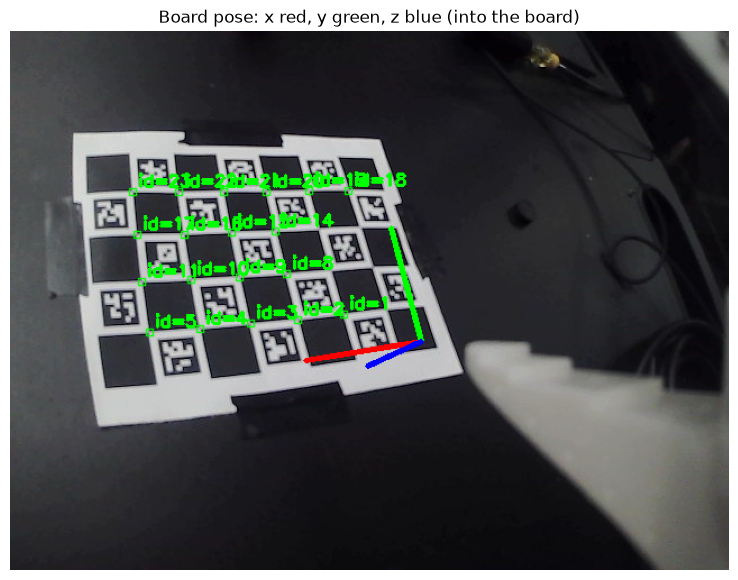

In [ ]:
if INTRINSICS_PATH.exists():
    intr = json.loads(INTRINSICS_PATH.read_text())
    K, dist = np.array(intr["k"]), np.array(intr["dist"])
    if (intr["width"], intr["height"]) != (w_img, h_img):
        print(f"WARNING: intrinsics are for {intr['width']}x{intr['height']}, image is {w_img}x{h_img}")
    print(f"Loaded {INTRINSICS_PATH} (RMS {intr['rms_px']:.2f} px)")
else:
    f = (w_img / 2) / math.tan(math.radians(70 / 2))
    K, dist = np.array([[f, 0, w_img / 2], [0, f, h_img / 2], [0, 0, 1.0]]), np.zeros(5)
    print(f"No {INTRINSICS_PATH} - using a ROUGH guess: f = {f:.0f} px, no distortion")
print("K =\n", np.round(K, 1))

pose = None
if ch_ids is not None and len(ch_ids) >= 6:
    obj, img_pts = board.matchImagePoints(ch_corners, ch_ids)
    obj, img_pts = obj.reshape(-1, 3), img_pts.reshape(-1, 2)
    ok, rvec, tvec = cv2.solvePnP(obj, img_pts, K, dist, flags=cv2.SOLVEPNP_IPPE)
    rvec, tvec = cv2.solvePnPRefineLM(obj, img_pts, K, dist, rvec, tvec)
    proj, _ = cv2.projectPoints(obj, rvec, tvec, K, dist)
    reproj = float(np.sqrt(np.mean(np.sum((proj.reshape(-1, 2) - img_pts) ** 2, axis=1))))
    R, _ = cv2.Rodrigues(rvec)
    pose = (R, tvec.reshape(3))
    tilt = math.degrees(math.acos(abs(R[2, 2])))  # angle between the camera axis and the board normal
    print(f"Board origin in camera frame: {np.round(tvec.ravel() * 1000, 1)} mm (distance {np.linalg.norm(tvec) * 1000:.0f} mm)")
    print(f"Viewing angle from straight-on: {tilt:.0f} deg · reprojection error {reproj:.2f} px")
    view = rgb.copy()
    cv2.aruco.drawDetectedCornersCharuco(view, ch_corners, ch_ids, (0, 255, 0))
    view = draw_axes(view, K, dist, rvec, tvec, 3 * SQUARE_MM / 1000)
    show(view, "Board pose: x red, y green, z blue (into the board)")
else:
    print("Need at least 6 ChArUco corners for a pose.")

## 5. Red cube detection

Red sits at both ends of OpenCV's hue scale (0–180), so two hue ranges are combined. Raise `s_min` / `v_min` in the settings cell if pale or dark things get picked up, and lower them if the cube is missed.

In [ ]:
hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
mask = cv2.inRange(hsv, (0, HSV["s_min"], HSV["v_min"]), (HSV["h_low_max"], 255, 255)) | cv2.inRange(
    hsv, (HSV["h_high_min"], HSV["s_min"], HSV["v_min"]), (180, 255, 255)
)
kernel = np.ones((5, 5), np.uint8)
mask = cv2.morphologyEx(cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel), cv2.MORPH_CLOSE, kernel)
contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cube = None
if contours:
    c = max(contours, key=cv2.contourArea)
    if cv2.contourArea(c) >= HSV["min_area"]:
        m = cv2.moments(c)
        (_, _), (_, _), angle = cv2.minAreaRect(c)
        cube = dict(u=m["m10"] / m["m00"], v=m["m01"] / m["m00"], angle=angle, area=cv2.contourArea(c), contour=c)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].imshow(mask, cmap="gray"); ax[0].set_title("Red mask"); ax[0].axis("off")
view = rgb.copy()
if cube:
    cv2.drawContours(view, [cube["contour"]], -1, (0, 255, 0), 2)
    cv2.circle(view, (int(cube["u"]), int(cube["v"])), 5, (255, 255, 0), -1)
ax[1].imshow(view); ax[1].axis("off")
ax[1].set_title(f"Cube at pixel ({cube['u']:.1f}, {cube['v']:.1f}), area {cube['area']:.0f} px" if cube else "No red cube found")
plt.show()

## 6. Where is the cube on the board?

The pixel is undistorted and turned into a ray from the camera. The ray is intersected with the plane of the cube's **top face**, which is `CUBE_SIZE_MM` above the board (negative z, since board z points into the table). Using the top face instead of the table avoids a parallax error. The pick script does the same, but in the robot's base frame (via forward kinematics and the hand-eye calibration) instead of the board's frame.

In [ ]:
if cube and pose:
    R, t = pose
    n = cv2.undistortPoints(np.array([[[cube["u"], cube["v"]]]]), K, dist).reshape(2)
    ray_cam = np.array([n[0], n[1], 1.0])
    # camera centre and ray direction expressed in the board frame
    origin, ray = -R.T @ t, R.T @ ray_cam
    plane_z = -CUBE_SIZE_MM / 1000
    s = (plane_z - origin[2]) / ray[2]
    p = origin + s * ray
    print(f"Cube centre on the board: x = {p[0] * 1000:.1f} mm, y = {p[1] * 1000:.1f} mm "
          f"(from the board's origin corner), camera distance {s * np.linalg.norm(ray) * 1000:.0f} mm")
    rvec, _ = cv2.Rodrigues(R)
    tip, _ = cv2.projectPoints(np.array([[p[0], p[1], 0.0]]), rvec, t, K, dist)
    view = draw_axes(rgb, K, dist, rvec, t, 3 * SQUARE_MM / 1000)
    cv2.line(view, (int(cube["u"]), int(cube["v"])), tuple(int(x) for x in tip.ravel()), (255, 255, 0), 2)
    cv2.circle(view, tuple(int(x) for x in tip.ravel()), 5, (255, 0, 255), -1)
    show(view, "Cube top-face centre (yellow) and the point below it on the board (magenta)")
else:
    print("Need both a board pose and a cube detection for this step.")

## 7. Summary: settings for the calibration scripts

In [ ]:
if BOARD:
    print("Pass these to 07_wrist_intrinsics.sh if they differ from the defaults (5x7, DICT_4X4_50, 22/30 mm):")
    print(f"  --squares-x {BOARD['squares_x']} --squares-y {BOARD['squares_y']} --dictionary {BOARD['dictionary']} "
          f"--square-mm {SQUARE_MM} --marker-mm {SQUARE_MM * BOARD['marker_ratio']:.1f}")
    if BOARD.get("legacy"):
        print("  NOTE: this is a legacy-pattern board; tell Claude so the scripts enable setLegacyPattern.")
    print("Measure the printed square and marker with a ruler: the marker ratio found here is only approximate.")